# CHASSIS Scenario Author — EDA синтетического корпуса

**Источник:** `../data/scenarios.jsonl`

In [2]:
from pathlib import Path
import json, re
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("chassis_corpus/data/scenarios.jsonl")
rows = [json.loads(line) for line in DATA.read_text(encoding="utf-8").splitlines() if line.strip()]
print("Запросов:", len(rows))
print("Независимых групп:", len({r["scenario_group_id"] for r in rows}))

Запросов: 48
Независимых групп: 36


In [3]:
def nested_count(node, key):
    if isinstance(node, dict):
        return int(key in node) + sum(nested_count(v, key) for v in node.values())
    if isinstance(node, list):
        return sum(nested_count(v, key) for v in node)
    return 0

df = pd.DataFrame([{
    **{k: r[k] for k in ["request_id","scenario_group_id","split","scenario_class","complexity","language","source_type","annotation_status"]},
    "text":r["text"], "words": len(re.findall(r"\S+",r["text"])),
    "actors": len(r["reference_dsl"].get("actors", [])),
    "triggers": nested_count(r["reference_dsl"].get("actors", []),"trigger"),
    "provenance_missing":not bool(r["reference_dsl"].get("provenance")),
    "assumptions_empty":not bool(r["reference_dsl"].get("assumptions")),
    "review_note":bool(r["review_notes"].strip())
} for r in rows])
display(df.head(6))

,request_id,scenario_group_id,split,scenario_class,complexity,language,source_type,annotation_status,text,words,actors,triggers,provenance_missing,assumptions_empty,review_note
0,req_001_a,group_001,few_shot_pool,pedestrian_crossing,simple,ru,user_supplied_example_adapted,needs_expert_review,Пешеход переходит ближайший к эго пешеходный п...,11,1,0,True,True,True
1,req_001_b,group_001,few_shot_pool,pedestrian_crossing,simple,ru,synthetic_paraphrase,needs_expert_review,Добавь пешехода со скоростью 5 метров в секунд...,13,1,0,True,True,True
2,req_002_a,group_002,few_shot_pool,pedestrian_crossing,simple,ru,synthetic_author_generated,needs_expert_review,Пешеход начинает переходить дорогу по ближайше...,9,1,0,True,True,False
3,req_002_b,group_002,few_shot_pool,pedestrian_crossing,simple,ru,synthetic_paraphrase,needs_expert_review,На ближайшем переходе перед эго человек перехо...,8,1,0,True,True,False
4,req_003_a,group_003,few_shot_pool,pedestrian_crossing,simple,ru,synthetic_author_generated,needs_expert_review,Женщина идет через нерегулируемый пешеходный п...,10,1,0,True,True,False
5,req_004_a,group_004,few_shot_pool,pedestrian_crossing,simple,ru,synthetic_author_generated,needs_expert_review,Пешеход стоит у правого края ближайшей зебры и...,9,1,0,True,True,False


## 1. Состав и репрезентативность
Это синтетически собранный корпус, а не случайная выборка реальных запросов. Ниже показано лишь покрытие проектных категорий.

Классы:


,requests
scenario_class,
pedestrian_crossing,9
occlusion,8
lead_braking,8
lane_change,7
composite,7
intersection,5
oncoming,4


Сложность:


,requests
complexity,
simple,24
medium,20
complex,4


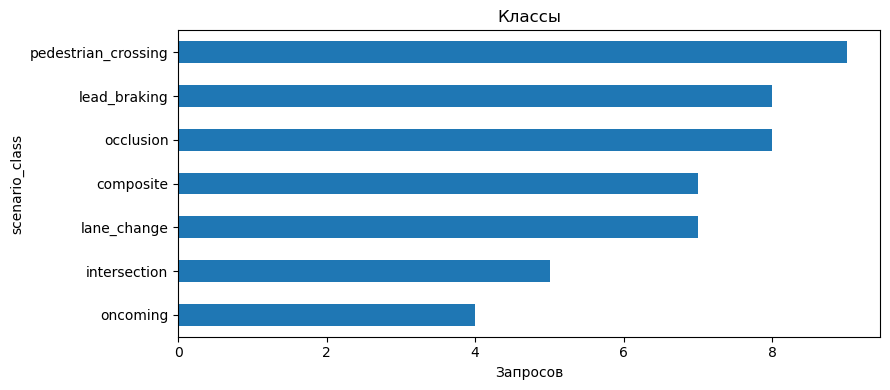

In [4]:
print("Классы:")
display(df.scenario_class.value_counts().to_frame("requests"))
print("Сложность:")
display(df.complexity.value_counts().to_frame("requests"))
fig,ax=plt.subplots(figsize=(9,4));df.scenario_class.value_counts().sort_values().plot.barh(ax=ax);ax.set(title="Классы",xlabel="Запросов");plt.tight_layout();plt.show()

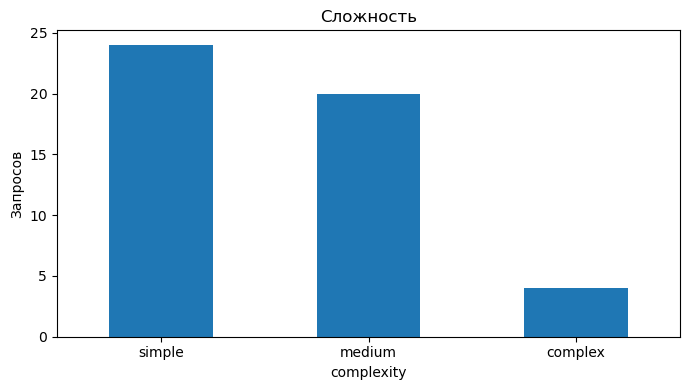

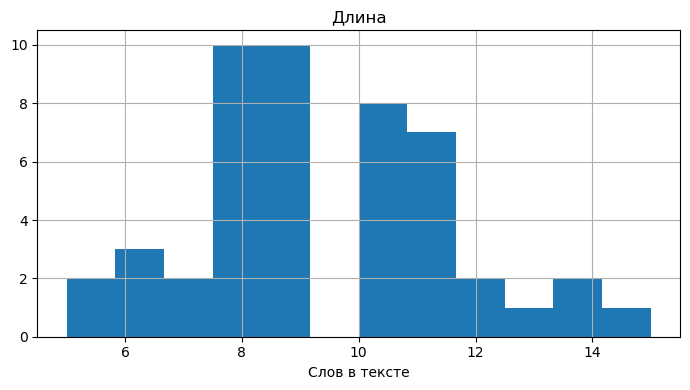

count    48.000000
mean      9.354167
std       2.197577
min       5.000000
25%       8.000000
50%       9.000000
75%      11.000000
max      15.000000
Name: words, dtype: float64


In [5]:
fig,ax=plt.subplots(figsize=(7,4));df.complexity.value_counts().reindex(["simple","medium","complex"]).plot.bar(ax=ax,rot=0);ax.set(title="Сложность",ylabel="Запросов");plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(7,4));df.words.hist(bins=12,ax=ax);ax.set(title="Длина",xlabel="Слов в тексте");plt.tight_layout();plt.show()
print(df.words.describe())

## 2. Содержимое DSL и риски качества
Проверки ниже относятся к **структуре**, а не к смысловой правильности. Пустой `assumptions` нельзя считать доказательством отсутствия допущений.

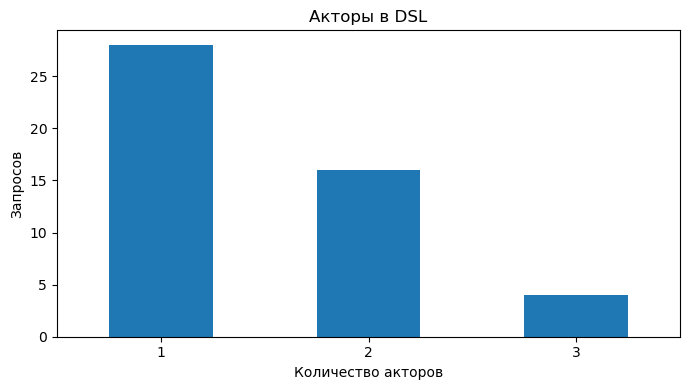

Запросы с триггерами: 11
Пустой provenance: 48
Пустой assumptions: 48
Требуют экспертного ревью: 48


In [6]:
fig,ax=plt.subplots(figsize=(7,4));df.actors.value_counts().sort_index().plot.bar(ax=ax,rot=0);ax.set(title="Акторы в DSL",xlabel="Количество акторов",ylabel="Запросов");plt.tight_layout();plt.show()
print("Запросы с триггерами:",int((df.triggers>0).sum()))
print("Пустой provenance:",int(df.provenance_missing.sum()))
print("Пустой assumptions:",int(df.assumptions_empty.sum()))
print("Требуют экспертного ревью:",int((df.annotation_status=="needs_expert_review").sum()))

## 3. Проверка сплитов и утечек
Группы перефразировок должны оставаться целиком в одном сплите.

In [7]:
by_split = df.groupby("split").agg(requests=("request_id","count"),groups=("scenario_group_id","nunique"))
display(by_split)
leaked_groups = df.groupby("scenario_group_id").split.nunique().loc[lambda x:x>1]
print("Группы в нескольких сплитах:",len(leaked_groups))
print("Дубликаты request_id:",int(df.request_id.duplicated().sum()))
normalized = df.text.str.strip().str.lower().str.replace(r"\s+"," ",regex=True)
print("Точные текстовые дубликаты:",int(normalized.duplicated().sum()))
display(pd.crosstab(df.scenario_class,df.split))

,requests,groups
split,,
dev,8,7
few_shot_pool,32,22
test,8,7


Группы в нескольких сплитах: 0
Дубликаты request_id: 0
Точные текстовые дубликаты: 0


split,dev,few_shot_pool,test
scenario_class,,,
composite,1,5,1
intersection,1,3,1
lane_change,1,5,1
lead_braking,2,5,1
occlusion,1,5,2
oncoming,1,2,1
pedestrian_crossing,1,7,1


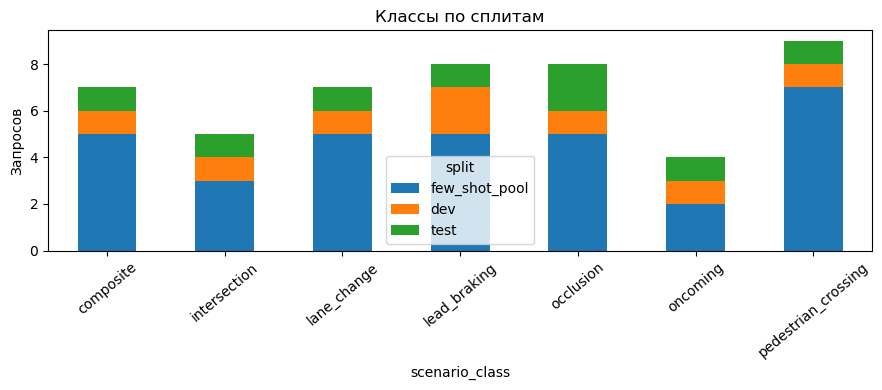

In [8]:
fig,ax=plt.subplots(figsize=(9,4));pd.crosstab(df.scenario_class,df.split)[["few_shot_pool","dev","test"]].plot.bar(stacked=True,ax=ax,rot=40);ax.set(title="Классы по сплитам",ylabel="Запросов");plt.tight_layout();plt.show()

## 4. Выводы
1. 48 запросов / 36 групп — достаточный старт для отладки пайплайна, но не для оценки качества на реальном распределении.
2. `provenance` и `assumptions` пусты во всех записях, экспертного gold нет.
3. Число сложных запросов и размер `dev/test` малы.
4. Сплиты не пересекаются по идентификаторам сценарных групп, но семантические дубликаты с **разными** идентификаторами пока не выявляются.
5. Следующий шаг — зафиксировать DSL v0.1 и провести экспертную разметку, затем собрать реальные запросы в закрытом контуре.